# 11 — Hyperparameter Optimization

[Previous](./10_Model_Comparison.ipynb) | [Repository guide](../README.md) | [Next](./12_Ensembling.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** improve the strongest starter models by tuning their settings without changing the data, features, folds, or metric.

We tune **CatBoost**, **LightGBM**, and the **multilayer perceptron (MLP)**. Logistic regression stays as the simple reference. The test data is not used for choosing settings.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## 1. Tuning vocabulary

- **Parameter:** a value learned from the training rows, such as a model weight.
- **Hyperparameter:** a setting chosen before training, such as tree depth.
- **Search space:** the allowed values we want to try.
- **Candidate / trial:** one complete combination of settings.
- **Cross-validation score:** the average result across the same five validation folds.
- **Rank:** `1` means the best average validation F1 among the tried candidates.
- **Best estimator:** the model rebuilt with the winning settings.
- **Overfitting gap:** training F1 minus validation F1. A large positive gap warns that the model learned the training rows better than unseen rows.

Tuning does not guarantee improvement. It is a controlled experiment whose result can also be “keep the starter settings.”


In [1]:
from time import perf_counter
import hashlib
import json
import warnings

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42
N_TRIALS = 8

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", message="X does not have valid feature names")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

fingerprint_values = pd.util.hash_pandas_object(
    train.sort_index(axis=1), index=True
).values.tobytes()
dataset_fingerprint = hashlib.sha256(fingerprint_values).hexdigest()[:12]

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Dataset fingerprint: {dataset_fingerprint}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
Dataset fingerprint: 3bc8d73b8f62


## 2. Freeze the experiment

Every candidate receives the same:

- 34 engineered feature candidates from Notebook 05;
- median/mode missing-value filling;
- numerical standardization and categorical one-hot encoding;
- original class balance;
- five stratified folds;
- F1 scoring at the default `0.50` probability threshold.

Only the model’s hyperparameters change. This makes any score difference interpretable.


In [4]:


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

## 3. Which settings will we tune?

### CatBoost

- `iterations`: number of boosting trees.
- `learning_rate`: how much each new tree changes the model.
- `depth`: maximum levels in each tree; deeper trees learn more complex interactions.
- `l2_leaf_reg`: penalty that discourages overly extreme leaf values.
- `random_strength`: randomness added while choosing splits; it can reduce overfitting.

### LightGBM

- `n_estimators`: number of boosting trees.
- `num_leaves`: maximum leaf regions in each tree.
- `max_depth`: maximum tree depth; `-1` means no explicit limit.
- `min_child_samples`: minimum rows allowed in a leaf; larger values make smoother rules.
- `subsample`: fraction of rows used by each tree.
- `colsample_bytree`: fraction of features considered by each tree.
- `reg_lambda`: L2 penalty that discourages overly complex predictions.

### MLP neural network

- `hidden_layer_sizes`: number and size of hidden layers. `(64, 32)` means two layers.
- `activation`: nonlinear function used by hidden neurons.
- `alpha`: penalty that shrinks large weights.
- `learning_rate_init`: initial size of each weight update.
- `batch_size`: number of rows used for one weight update.

**Common trade-off:** a smaller learning rate often needs more trees or training steps.


In [6]:
study_specs = {
    "CatBoost": {
        "starter": CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
        ),
        "space": {
            "model__iterations": [200, 300, 450, 600],
            "model__learning_rate": [0.025, 0.05, 0.08, 0.12],
            "model__depth": [4, 5, 6, 7, 8],
            "model__l2_leaf_reg": [1, 3, 5, 8, 12],
            "model__random_strength": [0.5, 1.0, 2.0],
        },
    },
    "LightGBM": {
        "starter": LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
        ),
        "space": {
            "model__n_estimators": [200, 300, 450, 600],
            "model__learning_rate": [0.025, 0.05, 0.08, 0.12],
            "model__num_leaves": [15, 31, 47, 63],
            "model__max_depth": [-1, 6, 8, 10],
            "model__min_child_samples": [10, 20, 35, 50],
            "model__subsample": [0.75, 0.90, 1.0],
            "model__colsample_bytree": [0.75, 0.90, 1.0],
            "model__reg_lambda": [0.0, 1.0, 3.0, 6.0],
        },
    },
    "Multilayer perceptron": {
        "starter": MLPClassifier(
            hidden_layer_sizes=(64, 32), max_iter=250, early_stopping=True,
            n_iter_no_change=15, random_state=RANDOM_STATE,
        ),
        "space": {
            "model__hidden_layer_sizes": [(32,), (64,), (64, 32), (96, 48), (128, 64)],
            "model__activation": ["relu", "tanh"],
            "model__alpha": [0.0001, 0.001, 0.01, 0.05],
            "model__learning_rate_init": [0.0003, 0.001, 0.003, 0.01],
            "model__batch_size": [64, 128, 256],
        },
    },
}

space_summary = pd.DataFrame([
    {
        "model": name,
        "settings searched": len(spec["space"]),
        "possible combinations": int(np.prod([len(values) for values in spec["space"].values()])),
        "trials run": N_TRIALS,
    }
    for name, spec in study_specs.items()
])
display(space_summary.style.hide(axis="index"))


model,settings searched,possible combinations,trials run
CatBoost,5,1200,8
LightGBM,8,36864,8
Multilayer perceptron,5,480,8


## 4. Step 1 — Measure the starter settings

We first rebuild the three starter models under the same conditions. This gives Notebook 11 its own fair before/after comparison.

The logistic model is repeated only as a **sanity-check reference**: extra complexity should clearly earn its cost.


In [7]:
folds = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y)
)

reference_models = {
    "Logistic regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    **{name: spec["starter"] for name, spec in study_specs.items()},
}

starter_rows = []
starter_predictions = {}
starter_scores = {}

for name, estimator in reference_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    start = perf_counter()
    class_probabilities = cross_val_predict(
        pipeline, X, y, cv=folds, method="predict_proba", n_jobs=1
    )
    # Column 0 = missed; column 1 = scored. Keep the scoring probability.
    probabilities = class_probabilities[:, 1]
    elapsed = perf_counter() - start
    predictions = (probabilities >= 0.50).astype(int)
    fold_f1 = []
    # Score each validation fold separately to check consistency.
    for unused_training_rows, validation_rows in folds:
        fold_score = f1_score(y.iloc[validation_rows], predictions[validation_rows])
        fold_f1.append(fold_score)
    starter_rows.append({
        "model": name,
        "version": "Starter",
        "oof_f1": f1_score(y, predictions),
        "mean_fold_f1": np.mean(fold_f1),
        "fold_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
        "fit_seconds": elapsed,
    })
    starter_predictions[name] = predictions
    starter_scores[name] = probabilities
    print(f"Finished {name}: OOF F1 {starter_rows[-1]['oof_f1']:.4f} in {elapsed:.1f}s")

starter_results = pd.DataFrame(starter_rows)
display(starter_results.style.hide(axis="index").format(precision=4))


Finished Logistic regression: OOF F1 0.8847 in 4.6s
Finished CatBoost: OOF F1 0.9462 in 12.9s
Finished LightGBM: OOF F1 0.9447 in 7.2s
Finished Multilayer perceptron: OOF F1 0.9456 in 14.8s


model,version,oof_f1,mean_fold_f1,fold_std,precision,recall,balanced_accuracy,accuracy,roc_auc,fit_seconds
Logistic regression,Starter,0.8847,0.8847,0.0061,0.8916,0.8779,0.8953,0.8970,0.9625,4.5970
CatBoost,Starter,0.9462,0.9462,0.0045,0.9488,0.9437,0.9510,0.9517,0.9927,12.8842
LightGBM,Starter,0.9447,0.9447,0.0056,0.9447,0.9447,0.9497,0.9502,0.9919,7.1785
Multilayer perceptron,Starter,0.9456,0.9456,0.0030,0.9472,0.9440,0.9505,0.9511,0.9918,14.8164


## 5. Step 2 — Randomized search

**Randomized search** samples a fixed number of combinations from a larger search space. It usually explores more variety than a small grid for the same computing budget.

For each of the eight candidates per model:

1. fit preprocessing only on the training part of each fold;
2. train the model with that candidate’s settings;
3. measure F1 on the untouched fold;
4. average the five fold scores;
5. refit the highest-ranked candidate on all training rows.

The random seed makes the sampled candidates reproducible.


In [8]:
searches = {}
candidate_frames = []

for name, spec in study_specs.items():
    print(f"Searching {name} ...")
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", spec["starter"]),
    ])
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=spec["space"],
        n_iter=N_TRIALS,
        scoring="f1",
        cv=folds,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        return_train_score=True,
        error_score="raise",
    )
    start = perf_counter()
    search.fit(X, y)
    elapsed = perf_counter() - start
    searches[name] = search

    table = pd.DataFrame(search.cv_results_)
    compact = pd.DataFrame({
        "model": name,
        "candidate": np.arange(1, len(table) + 1),
        "mean_cv_f1": table["mean_test_score"],
        "fold_std": table["std_test_score"],
        "mean_train_f1": table["mean_train_score"],
        "overfit_gap": table["mean_train_score"] - table["mean_test_score"],
        "mean_fit_seconds": table["mean_fit_time"],
        "rank": table["rank_test_score"].astype(int),
        "parameters": [
            ", ".join(
                f"{key.replace('model__', '')}={value}"
                for key, value in params.items()
            )
            for params in table["params"]
        ],
    })
    candidate_frames.append(compact)
    print(
        f"Best mean CV F1: {search.best_score_:.4f} | "
        f"{N_TRIALS} candidates completed in {elapsed:.1f}s"
    )

candidate_results = pd.concat(candidate_frames, ignore_index=True)


Searching CatBoost ...
Best mean CV F1: 0.9464 | 8 candidates completed in 219.4s
Searching LightGBM ...
Best mean CV F1: 0.9449 | 8 candidates completed in 79.2s
Searching Multilayer perceptron ...
Best mean CV F1: 0.9472 | 8 candidates completed in 329.8s


## 6. Read the search results

- A higher dot means better average validation F1.
- The vertical line around a dot is ordinary fold-to-fold variation.
- The dashed line is that model’s starter score.
- `overfit gap` is supporting evidence, not a score to maximize. Smaller is generally safer when validation F1 is similar.

Small differences inside the error bars should not be treated as certain wins.


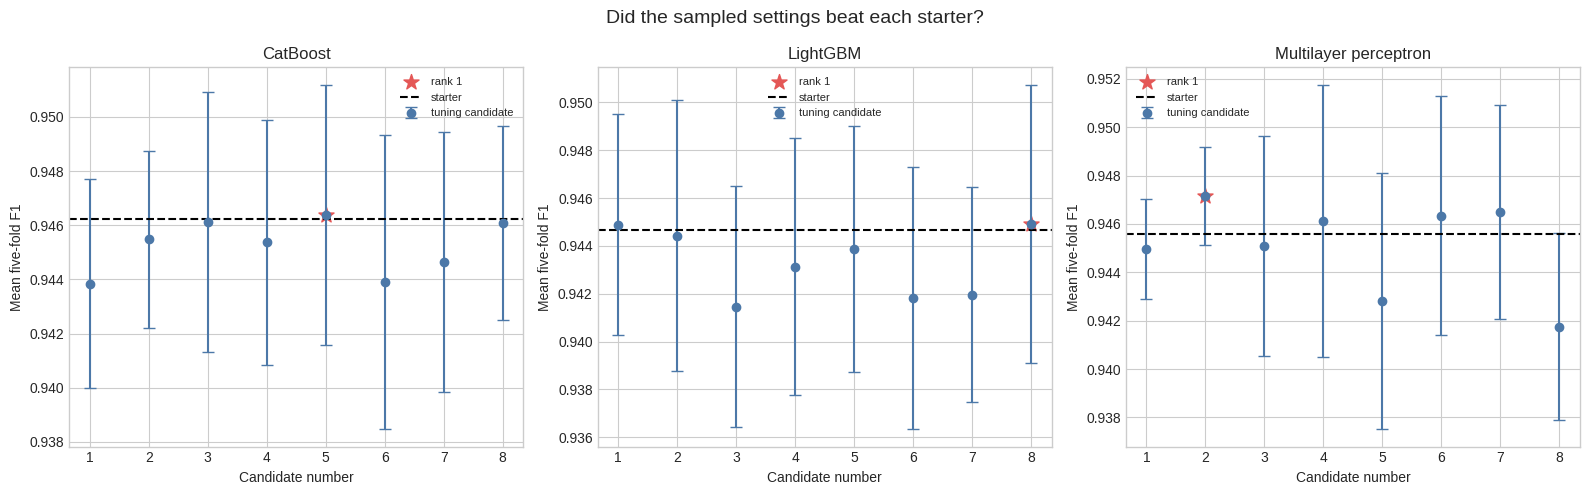

model,rank,mean_cv_f1,fold_std,overfit_gap,mean_fit_seconds,parameters
CatBoost,1,0.9464,0.0048,+0.0199,5.4,"random_strength=0.5, learning_rate=0.025, l2_leaf_reg=5, iterations=300, depth=8"
CatBoost,2,0.9461,0.0048,+0.0227,7.9,"random_strength=2.0, learning_rate=0.025, l2_leaf_reg=12, iterations=450, depth=8"
CatBoost,3,0.9461,0.0036,+0.0212,2.0,"random_strength=0.5, learning_rate=0.08, l2_leaf_reg=5, iterations=300, depth=5"
LightGBM,1,0.9449,0.0058,+0.0220,1.7,"subsample=1.0, reg_lambda=1.0, num_leaves=15, n_estimators=600, min_child_samples=10, max_depth=8, learning_rate=0.025, colsample_bytree=0.75"
LightGBM,2,0.9449,0.0046,+0.0234,1.0,"subsample=0.75, reg_lambda=1.0, num_leaves=15, n_estimators=300, min_child_samples=35, max_depth=-1, learning_rate=0.05, colsample_bytree=0.9"
LightGBM,3,0.9444,0.0057,+0.0247,1.4,"subsample=1.0, reg_lambda=3.0, num_leaves=63, n_estimators=300, min_child_samples=10, max_depth=6, learning_rate=0.025, colsample_bytree=0.75"
Multilayer perceptron,1,0.9472,0.0020,+0.0199,7.2,"learning_rate_init=0.003, hidden_layer_sizes=(96, 48), batch_size=256, alpha=0.01, activation=tanh"
Multilayer perceptron,2,0.9465,0.0044,+0.0115,9.0,"learning_rate_init=0.0003, hidden_layer_sizes=(64, 32), batch_size=128, alpha=0.0001, activation=tanh"
Multilayer perceptron,3,0.9463,0.0049,+0.0157,5.2,"learning_rate_init=0.0003, hidden_layer_sizes=(96, 48), batch_size=256, alpha=0.01, activation=relu"


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for axis, (name, group) in zip(axes, candidate_results.groupby("model", sort=False)):
    group = group.sort_values("candidate")
    starter_mean = starter_results.loc[
        starter_results["model"].eq(name), "mean_fold_f1"
    ].iloc[0]
    best_row = group.loc[group["rank"].idxmin()]

    axis.errorbar(
        group["candidate"], group["mean_cv_f1"], yerr=group["fold_std"],
        fmt="o", capsize=4, color="#4C78A8", label="tuning candidate",
    )
    axis.scatter(
        best_row["candidate"], best_row["mean_cv_f1"],
        s=130, color="#E45756", marker="*", label="rank 1",
    )
    axis.axhline(starter_mean, color="black", linestyle="--", label="starter")
    axis.set(
        title=name,
        xlabel="Candidate number",
        ylabel="Mean five-fold F1",
        xticks=group["candidate"],
    )
    axis.legend(fontsize=8)

fig.suptitle("Did the sampled settings beat each starter?", fontsize=14)
plt.tight_layout()
plt.show()

top_candidates = candidate_results.loc[candidate_results["rank"] <= 3].sort_values(
    ["model", "rank"]
)
display(
    top_candidates[
        ["model", "rank", "mean_cv_f1", "fold_std", "overfit_gap", "mean_fit_seconds", "parameters"]
    ].style.hide(axis="index").format({
        "mean_cv_f1": "{:.4f}",
        "fold_std": "{:.4f}",
        "overfit_gap": "{:+.4f}",
        "mean_fit_seconds": "{:.1f}",
    })
)


## 7. Step 3 — Re-evaluate the winning settings

The search score ranks candidates. We now create fresh **out-of-fold (OOF)** predictions for each winner so the before/after metrics use exactly the same format.

This is still the same tuning validation evidence, not a brand-new final test. Reusing folds to select and report the winner can make the gain look slightly optimistic; nested cross-validation is the stricter alternative described later.


In [10]:
tuned_rows = []
tuned_predictions = {}
tuned_scores = {}

for name, search in searches.items():
    start = perf_counter()
    class_probabilities = cross_val_predict(
        search.best_estimator_, X, y,
        cv=folds, method="predict_proba", n_jobs=1,
    )
    # Column 0 = missed; column 1 = scored. Keep the scoring probability.
    probabilities = class_probabilities[:, 1]
    elapsed = perf_counter() - start
    predictions = (probabilities >= 0.50).astype(int)
    fold_f1 = []
    # Score each validation fold separately to check consistency.
    for unused_training_rows, validation_rows in folds:
        fold_score = f1_score(y.iloc[validation_rows], predictions[validation_rows])
        fold_f1.append(fold_score)
    tuned_rows.append({
        "model": name,
        "version": "Tuned",
        "oof_f1": f1_score(y, predictions),
        "mean_fold_f1": np.mean(fold_f1),
        "fold_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
        "fit_seconds": elapsed,
    })
    tuned_predictions[name] = predictions
    tuned_scores[name] = probabilities
    print(f"Finished tuned {name}: OOF F1 {tuned_rows[-1]['oof_f1']:.4f} in {elapsed:.1f}s")

tuned_results = pd.DataFrame(tuned_rows)
model_names = list(study_specs)
comparison = pd.concat([
    starter_results.loc[starter_results["model"].isin(model_names)],
    tuned_results,
], ignore_index=True)

improvement = (
    starter_results.loc[starter_results["model"].isin(model_names), ["model", "oof_f1"]]
    .rename(columns={"oof_f1": "starter_f1"})
    .merge(
        tuned_results[["model", "oof_f1"]].rename(columns={"oof_f1": "tuned_f1"}),
        on="model",
    )
)
improvement["change"] = improvement["tuned_f1"] - improvement["starter_f1"]
display(improvement.style.hide(axis="index").format({
    "starter_f1": "{:.4f}", "tuned_f1": "{:.4f}", "change": "{:+.4f}"
}))


Finished tuned CatBoost: OOF F1 0.9464 in 26.9s
Finished tuned LightGBM: OOF F1 0.9449 in 9.0s
Finished tuned Multilayer perceptron: OOF F1 0.9471 in 37.2s


model,starter_f1,tuned_f1,change
CatBoost,0.9462,0.9464,+0.0001
LightGBM,0.9447,0.9449,+0.0003
Multilayer perceptron,0.9456,0.9471,+0.0016


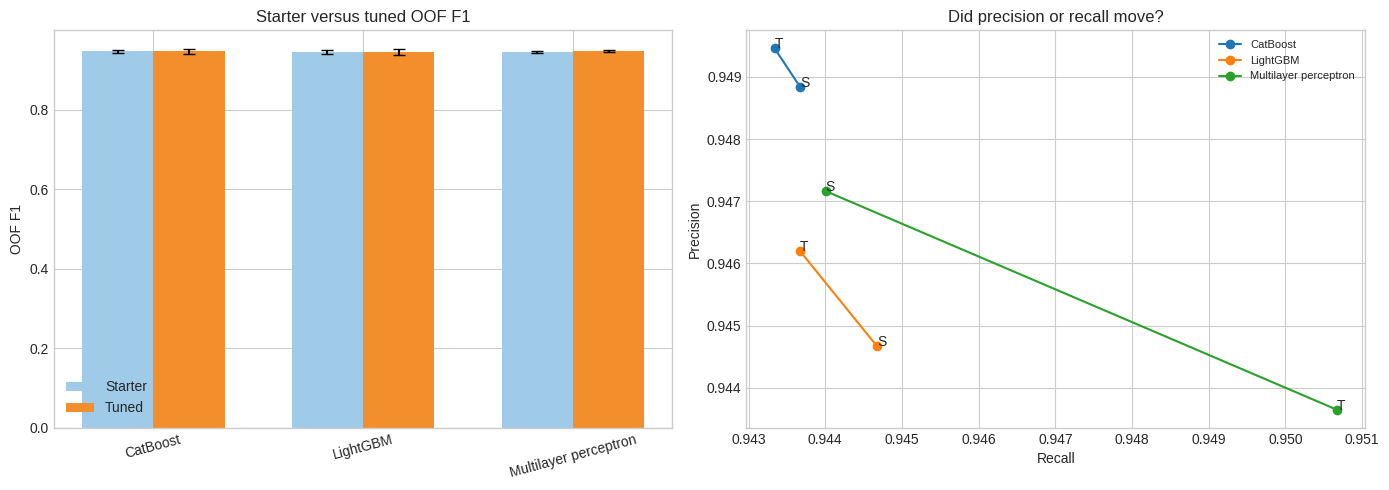

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(model_names))
width = 0.34
for offset, version, color in [
    (-width / 2, "Starter", "#A0CBE8"),
    (width / 2, "Tuned", "#F28E2B"),
]:
    part = comparison.loc[comparison["version"].eq(version)].set_index("model").loc[model_names]
    axes[0].bar(
        x + offset, part["oof_f1"], width,
        yerr=part["fold_std"], capsize=4, label=version, color=color,
    )
axes[0].set(
    title="Starter versus tuned OOF F1",
    ylabel="OOF F1",
    xticks=x,
    xticklabels=model_names,
)
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend()

for name in model_names:
    part = comparison.loc[comparison["model"].eq(name)].set_index("version")
    axes[1].plot(
        part.loc[["Starter", "Tuned"], "recall"],
        part.loc[["Starter", "Tuned"], "precision"],
        marker="o", label=name,
    )
    axes[1].annotate("S", (part.loc["Starter", "recall"], part.loc["Starter", "precision"]))
    axes[1].annotate("T", (part.loc["Tuned", "recall"], part.loc["Tuned", "precision"]))
axes[1].set(
    title="Did precision or recall move?",
    xlabel="Recall",
    ylabel="Precision",
)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


### Concrete dataset example: what tuning changed

The table shows eight penalties whose predicted probabilities changed most or whose class changed for several models.

- Probability near `1` means “scored” is more likely.
- Probability at least `0.50` becomes class `1`.
- `starter` and `tuned` are both OOF predictions, so the displayed row was excluded from that fold’s training data.


In [12]:
change_count = np.sum(
    np.column_stack([
        starter_predictions[name] != tuned_predictions[name]
        for name in model_names
    ]),
    axis=1,
)
largest_probability_shift = np.max(
    np.column_stack([
        np.abs(starter_scores[name] - tuned_scores[name])
        for name in model_names
    ]),
    axis=1,
)
priority = 10 * change_count + largest_probability_shift
example_index = np.argsort(priority)[-8:][::-1]

# Build the table one column at a time.
table_columns = {}
table_columns['actual'] = y.iloc[example_index].to_numpy()
for name in model_names:
    table_columns[f'{name} starter p'] = starter_scores[name][example_index]
for name in model_names:
    table_columns[f'{name} tuned p'] = tuned_scores[name][example_index]
table_columns['models changing class'] = change_count[example_index]
example = pd.DataFrame(table_columns, index=train.iloc[example_index]['id'].rename('penalty id'))
display(example.style.format(precision=3))


,actual,CatBoost starter p,LightGBM starter p,Multilayer perceptron starter p,CatBoost tuned p,LightGBM tuned p,Multilayer perceptron tuned p,models changing class
penalty id,,,,,,,,
6684,1,0.501,0.562,0.328,0.483,0.466,0.978,3
18178,0,0.422,0.498,0.765,0.519,0.515,0.177,3
15863,1,0.491,0.362,0.239,0.546,0.536,0.822,3
9330,0,0.495,0.495,0.269,0.531,0.584,0.757,3
7272,1,0.455,0.404,0.472,0.525,0.583,0.838,3
17325,0,0.519,0.412,0.614,0.492,0.523,0.255,3
19296,1,0.480,0.373,0.804,0.511,0.528,0.481,3
11948,0,0.485,0.274,0.310,0.570,0.532,0.556,3


## 8. Decision

We keep a tuned configuration only if its OOF F1 improves meaningfully without a worrying fold variation or overfitting gap.

The highest tuned F1 becomes a candidate for Notebook 12, not an automatic final model. Ensembling needs strong models that also make different errors.


In [13]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

best_tuned = tuned_results.sort_values("oof_f1", ascending=False).iloc[0]
best_name = best_tuned["model"]
best_starter_f1 = starter_results.loc[
    starter_results["model"].eq(best_name), "oof_f1"
].iloc[0]

print(f"Best tuned model: {best_name}")
print(f"OOF F1: {best_tuned['oof_f1']:.4f}")
print(f"Change from its starter: {best_tuned['oof_f1'] - best_starter_f1:+.4f}")
print("Best settings:")
for key, value in searches[best_name].best_params_.items():
    print(f"  {key.replace('model__', '')}: {value}")

best_parameter_rows = []
serializable_best_parameters = {}
for name, search in searches.items():
    clean_params = {}
    for key, value in search.best_params_.items():
        clean_key = key.replace("model__", "")
        clean_value = list(value) if isinstance(value, tuple) else value
        clean_params[clean_key] = clean_value
        best_parameter_rows.append({"model": name, "setting": clean_key, "value": str(value)})
    serializable_best_parameters[name] = clean_params

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)

candidate_results.to_csv(results_dir / "11_tuning_candidates.csv", index=False)
comparison.to_csv(results_dir / "11_starter_vs_tuned.csv", index=False)
with (results_dir / "11_best_hyperparameters.json").open("w", encoding="utf-8") as handle:
    json.dump(serializable_best_parameters, handle, indent=2)

print(f"Saved tuning artifacts to: {results_dir}")


Best tuned model: Multilayer perceptron
OOF F1: 0.9471
Change from its starter: +0.0016
Best settings:
  learning_rate_init: 0.003
  hidden_layer_sizes: (96, 48)
  batch_size: 256
  alpha: 0.01
  activation: tanh
Saved tuning artifacts to: /kaggle/working


## Other useful optimization methods

- **Grid search:** runs every listed combination. Easy to understand, but combinations grow very quickly.
- **Bayesian optimization:** uses earlier trials to choose promising next settings instead of sampling blindly.
- **Optuna:** a popular optimization library that supports Bayesian search, pruning, and helpful visualizations.
- **Hyperopt:** another library for guided search across parameter spaces.
- **Successive halving:** starts many candidates with a small resource budget and keeps only promising ones.
- **Hyperband:** repeats successive halving with different resource schedules.
- **Early stopping:** stops one training run when its validation score no longer improves. Our MLP uses an internal early-stopping split; the boosting searches use fixed tree counts for a clean comparison.
- **Nested cross-validation:** an outer fold estimates performance while an inner fold tunes settings. It is more honest but much more expensive.

Randomized search is used here because it is built into scikit-learn, reproducible, and clear enough for a first tuning notebook.


## Why this decision is justified

**Technical evidence:** every candidate used identical features, preprocessing, folds, and F1 scoring. We checked average validation F1, fold variation, training–validation gap, precision, recall, ROC-AUC, and runtime before choosing.

**Theoretical reason:** tuning changes a model’s complexity, regularization, and learning speed. The selected settings should improve generalization—not merely fit the training rows more closely.
